In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import scanpy as sc

import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

from tifffile import imread, imwrite

import os

from shapely.geometry import Polygon

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [6]:
# Load the image file
# Change dir_base as needed to the directory where the downloaded example data is stored
dir_base = '/home/lalonso/PhD/VisHD/data/'
filename = 'Visium_HD_Mouse_Small_Intestine_tissue_image.btf'
img = imread(dir_base + filename)

# Load the pretrained model
# model = StarDist2D.from_pretrained('2D_versatile_he')

In [4]:
import pickle

labels_path = dir_base + 'StarDist/labels.pickle'
polys_path = dir_base + 'StarDist/polys.pickle'

# Check if the labels and polys are already computed and saved
if os.path.exists(labels_path) and os.path.exists(polys_path):
    # Load the labels and polys from files
    with open(labels_path, 'rb') as f:
        labels = pickle.load(f)
    with open(polys_path, 'rb') as f:
        polys = pickle.load(f)
    print("Loaded labels and polys from disk.")
else:
    # If not available, compute them
    
    # Predict cell nuclei using the normalized image
    # Adjust nms_thresh and prob_thresh as needed
    labels, polys = model.predict_instances_big(img, axes='YXC', block_size=4096, prob_thresh=0.01,nms_thresh=0.001, min_overlap=128, context=128, normalizer=None, n_tiles=(4,4,1))
    
    # Save the computed labels and polys to disk
    with open(labels_path, 'wb') as f:
        pickle.dump(labels, f, protocol=pickle.HIGHEST_PROTOCOL)
    with open(polys_path, 'wb') as f:
        pickle.dump(polys, f, protocol=pickle.HIGHEST_PROTOCOL)
    print("Computed labels and polys and saved to disk.")

Loaded labels and polys from disk.


In [5]:
from tqdm import tqdm

xmin, xmax, ymin, ymax = 0, 0, 0, 0

# Creating a list to store Polygon geometries
geometries = []
ROI = []

# Iterating through each nuclei in the 'polys' DataFrame
for nuclei in tqdm(range(len(polys['coord']))):

    # Extracting coordinates for the current nuclei and converting them to (y, x) format
    coords = [(y, x) for x, y in zip(polys['coord'][nuclei][0], polys['coord'][nuclei][1])]

    # Creating a Polygon geometry from the coordinates
    geometries.append(Polygon(coords))
    for x, y in zip(polys['coord'][nuclei][0], polys['coord'][nuclei][1]):
        if (x >= xmin) & (x <= xmax) & (y >= ymin) & (y <= ymax):
            continue
        else:
            ROI.append(False)
            break
    else:
        ROI.append(True)

# Creating a GeoDataFrame using the Polygon geometries
gdf = gpd.GeoDataFrame(geometry=geometries)
gdf['id'] = [f"ID_{i+1}" for i, _ in enumerate(gdf.index)]
gdf['area'] = gdf['geometry'].area
gdf['isinROI'] = ROI

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 369005/369005 [00:16<00:00, 22710.19it/s]


In [6]:
print(f"Total number of cells: {len(polys['coord'])}")
print(f"Total number of cells in ROI: {sum(gdf['isinROI'])}")

Total number of cells: 369005
Total number of cells in ROI: 0


In [18]:
bin_width = 2
raw_h5_file = dir_base + 'binned_outputs/' + f'square_00{bin_width}um/' + 'filtered_feature_bc_matrix.h5'
adata = sc.read_10x_h5(raw_h5_file)

/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [19]:
# Load the Spatial Coordinates
tissue_position_file = dir_base + 'binned_outputs/' + f'square_00{bin_width}um/' + 'spatial/tissue_positions.parquet'
df_tissue_positions = pd.read_parquet(tissue_position_file)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata.obs =  pd.merge(adata.obs, df_tissue_positions, left_index=True, right_index=True)

# Bins2Spots

In [15]:
from bokeh_server.data.utils.bins2spots import Bins2Spots

In [20]:
b2s = Bins2Spots(adata, df_tissue_positions)
adata_v2 = b2s.convert(normalize=False)

11222500it [01:06, 167600.01it/s]
100%|██████████| 77/77 [00:00<00:00, 275.51it/s]
/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/lalonso/PhD/VisHD/.venv/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [13]:
# b2s.bin_points.cx[0:1000,0:1000].to_file('dataframe.geojson', driver='GeoJSON')

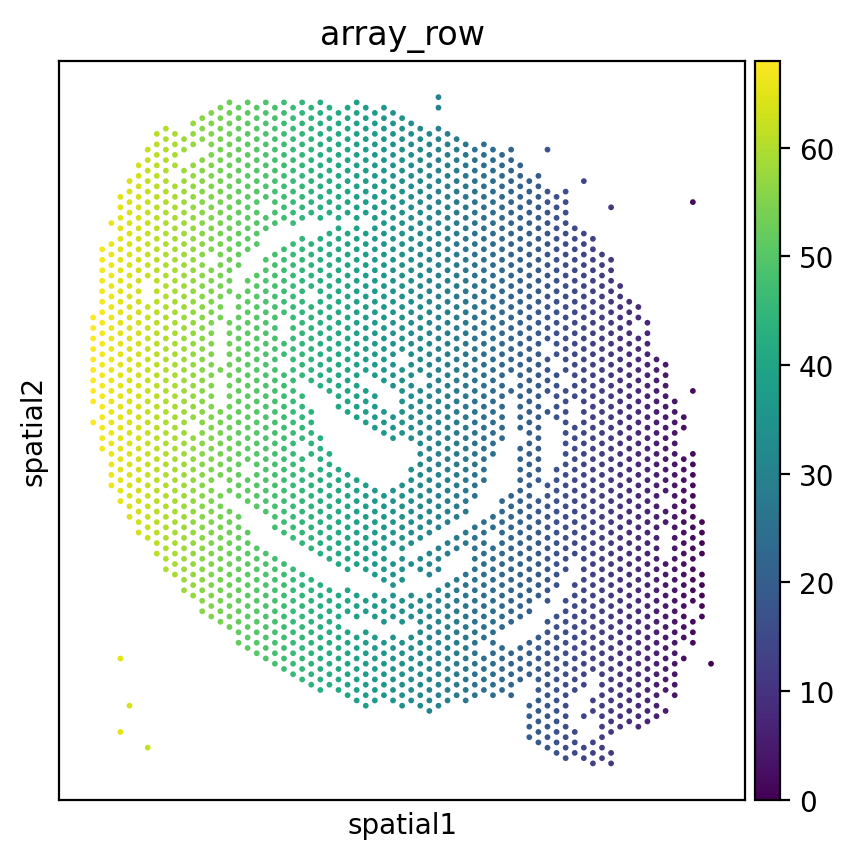

In [21]:
sc.pl.spatial(adata_v2, color="array_row", spot_size=b2s.converter.get_pixels(b2s.converter.visiumV2.SPOT_DIAMETER))

# Plot image

In [1]:
from bokeh.io import output_notebook
output_notebook()

Loading BokehJS ...

In [52]:
from src.parser import GeoDataFrameToColumnDataSource

In [53]:
polygons = GeoDataFrameToColumnDataSource(b2s.spot_polygons)

In [160]:
p = figure(tools='pan,wheel_zoom,box_zoom,reset', width=400, height=400)
p.circle(x='x', y='y', radius='radius', source=polygons.generate_cds())
show(p)

In [54]:
points = GeoDataFrameToColumnDataSource(b2s.bin_points)

In [62]:
p = figure(tools='pan,wheel_zoom,box_zoom,reset', width=400, height=400)
p.scatter(x='x', y='y', size=4, color='olive', alpha=0.5, line_width=1, source=points.generate_cds(bbox=bbox, offset=7.32/2), marker='square')
show(p)

NameError: name 'bbox' is not defined

In [ ]:
p = figure(tools='pan,wheel_zoom,box_zoom,reset', width=400, height=400)
p.circle(x='x', y='y', radius='radius', source=polygons.generate_cds(bbox=bbox, offset=7.32/2))
p.scatter(x='x', y='y', size=4, color='olive', alpha=0.5, line_width=1, source=points.generate_cds(bbox=bbox, offset=7.32/2), marker='square')
show(p)

# Tile source

In [10]:
from bokeh.plotting import figure, show
from bokeh.models import WMTSTileSource

# Setup Bokeh figure
max_dim = max(img.shape[:2])
p = figure(x_range=(0, max_dim), y_range=(0, max_dim))  # Adjust according to your image size

# URL for the tile server, adjust port and address as necessary
custom_tile = WMTSTileSource(url = "http://localhost:8000/{Z}/{X}/{Y}", tile_size=256, max_zoom=1, min_zoom=0, wrap_around=False, x_origin_offset=0, y_origin_offset=0, initial_resolution=max_dim/256)
p.add_tile(custom_tile)

show(p)

In [139]:
from bokeh.plotting import figure, show
from bokeh.models import WMTSTileSource, CheckboxGroup, CustomJS, HoverTool
from bokeh.layouts import column

# Setup Bokeh figure
max_dim = max(img.shape[:2])
p = figure(x_range=(0, max_dim), y_range=(0, max_dim))  # Adjust according to your image size
p.grid.visible = False

# URL for the tile server, adjust port and address as necessary
custom_tile = WMTSTileSource(url = "http://localhost:8000/{Z}/{X}/{Y}", tile_size=256, max_zoom=6, min_zoom=0, wrap_around=False, x_origin_offset=0, y_origin_offset=0, initial_resolution=max_dim/256)
p.add_tile(custom_tile)

source = polygons.generate_cds(width=img.shape[0], height=img.shape[1])
rect_glyph = p.circle(x='x', y='y', radius='radius', alpha=0.5, hover_color="pink", source=source)
hover = HoverTool(tooltips=[("Spot", "x: @x, y: @y")], renderers=[rect_glyph])
p.add_tools(hover)

# Create a select widget
checkbox = CheckboxGroup(labels=["Show spots"], active=[0])

# JS callback to toggle visibility of the glyph based on checkbox's active list
callback = CustomJS(args=dict(glyph=rect_glyph, checkbox=checkbox), code="""
    glyph.visible = checkbox.active.includes(0);  // Check if the first checkbox is checked
""")

# Connect the CheckboxGroup with the callback
checkbox.js_on_change('active', callback)

# Layout setup
layout = column(checkbox, p)

# Show the plot and widget
show(layout)


In [141]:
from bokeh.plotting import figure, show
from bokeh.models import WMTSTileSource, CheckboxGroup, CustomJS, HoverTool
from bokeh.layouts import column

# Setup Bokeh figure
max_dim = max(img.shape[:2])
p = figure(x_range=(0, max_dim), y_range=(0, max_dim))  # Adjust according to your image size
p.grid.visible = False

# URL for the tile server, adjust port and address as necessary
custom_tile = WMTSTileSource(url = "http://localhost:8000/{Z}/{X}/{Y}", tile_size=256, max_zoom=6, min_zoom=0, wrap_around=False, x_origin_offset=0, y_origin_offset=0, initial_resolution=max_dim/256)
p.add_tile(custom_tile)

source = points.generate_cds(bbox=[8000,9000,8000,9000], width=img.shape[0], height=img.shape[1])
rect_glyph = p.rect(x='x', y='y', width=7.33, height=7.33, hover_color="pink", line_width=0.5, fill_alpha=0.5, source=source)
rect_glyph.visible = False
hover = HoverTool(tooltips=[("Spot", "x: @x, y: @y")], renderers=[rect_glyph])
p.add_tools(hover)

callback = CustomJS(args=dict(rg=rect_glyph, xr=p.x_range, yr=p.y_range), code="""
    var xrange = xr.end - xr.start;
    var yrange = yr.end - yr.start;
    rg.visible = (xrange < 1000 && yrange < 1000);
""")

# Attach the update function to range changes
p.x_range.js_on_change('end', callback)
p.y_range.js_on_change('end', callback)

# Show the plot and widget
show(p)


parser.py (11): Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`


In [12]:
from bokeh.plotting import figure, show
from bokeh.models import WMTSTileSource, CheckboxGroup, CustomJS, HoverTool
from bokeh.layouts import column
from bokeh.models import ColumnDataSource

# Setup Bokeh figure
max_dim = max(img.shape[:2])
# p = figure(x_range=(0, max_dim), y_range=(0, max_dim))  # Adjust according to your image size
p = figure(x_range=(100, 200), y_range=(100, 200))
p.grid.visible = False

source = ColumnDataSource(data={'x': [], 'y': []})
rect_glyph = p.rect(x='x', y='y', width=7.33, height=7.33, hover_color="pink", fill_alpha=0.5, source=source)
rect_glyph.visible = False
hover = HoverTool(tooltips=[("Spot", "x: @x, y: @y")], renderers=[rect_glyph])
p.add_tools(hover)

callback = CustomJS(args=dict(rg=rect_glyph, xr=p.x_range, yr=p.y_range, source=source), code="""
    // Debounce setup
    var timeout = null;

    function updateData() {
        var left = xr.start;
        var right = xr.end;
        var bottom = yr.start;
        var top = yr.end;
        rg.visible = ((right - left) < 1000 && (top - bottom) < 1000);
        
        if (rg.visible) {
            var xhr = new XMLHttpRequest();
            var url = `http://localhost:8001/get_data?left=${left-50}&right=${right+50}&top=${top+50}&bottom=${bottom-50}`;
            xhr.open('GET', url);
            xhr.onload = function() {
                if (xhr.status === 200) {
                    var newData = JSON.parse(xhr.responseText);
                    source.data = newData;
                }
            };
            xhr.send();
        }
    }

    // Clear the previous timeout if it exists
    if (timeout) {
        clearTimeout(timeout);
    }

    // Set a new timeout
    timeout = setTimeout(updateData, 1000);  // 1000 milliseconds delay
""")

# Attach the update function to range changes
p.x_range.js_on_change('end', callback)
p.y_range.js_on_change('end', callback)

# Show the plot and widget
show(p)

In [9]:
from bokeh.plotting import figure, show
from bokeh.models import ColumnDataSource, Slider, CustomJS
from bokeh.layouts import column
from bokeh.tile_providers import get_provider, Vendors

# Create a plot with a tile source
p = figure(x_range=(-2000000, 6000000), y_range=(-1000000, 7000000),
           x_axis_type="mercator", y_axis_type="mercator", sizing_mode="stretch_width", height=400)
tile_provider = get_provider(Vendors.CARTODBPOSITRON)
p.add_tile(tile_provider)

# Overlay with a big rectangle (covering the area of the tiles)
source = ColumnDataSource({'x': [0], 'y': [0], 'width': [12000000], 'height': [14000000], 'alpha': [0.0]})
overlay = p.rect('x', 'y', 'width', 'height', source=source, color='white', alpha='alpha', level='overlay')

# Create a slider to control the alpha of the overlay
slider = Slider(start=0.0, end=1.0, value=1.0, step=0.01, title="Image alpha")

# JavaScript to update the alpha of the overlay rectangle
update_alpha = CustomJS(args=dict(source=source), code="""
    const data = source.data;
    const alpha = cb_obj.value;
    data['alpha'][0] = 1 - alpha;
    source.change.emit();
""")
slider.js_on_change('value', update_alpha)

# Layout
layout = column(p, slider)

# Show the plot
show(layout)
